# Gradient Map  
Explores the gradients of neural networks trained in notebook 3. Each gradient is the same size as the input to the network and gives a (standardized) measure of the sensitivity of the output to the input on a given day.

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import netCDF4
from pathlib import Path
from datetime import datetime
import json
import torch
from matplotlib.colors import LogNorm

In [2]:
from helpers.data_funcs import make_index #need to restart kernel to get these updated!!
from helpers.data_funcs import IcepackDataset
from helpers.data_funcs import read_mod_file
from helpers.models_funcs import train
from helpers.models_funcs import validate
from helpers.models_funcs import evaluate
from helpers.models_funcs import unpack

In [3]:
from helpers.network_architectures import *
from helpers.data_funcs import *
import torch.nn as nn
from torch.utils.data import Subset, DataLoader
from tabulate import tabulate

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## Config

In [5]:
SPLIT_NAME = "Tsno"
CLEAN_NAME = "ksno16_Tsno"
EXPERIMENT_NAME = "CNN_MSE"
target_col = 0

In [6]:
GROUPED_VARS = {"Tsno", "vsno", "aice", "vice"}

In [128]:
units = {"Tsno": "Celsius", "vsno": "Meters", "aice": "Fraction of ice", "vice": "Meters", "Tair":"Kelvin", "fcondtop":"W/m^2"}

In [18]:
head = 5

## Loading Data

In [7]:
CLEAN_DIR = Path(f"/projects/dagr5998/cleaned_data/01icepack_array_output/{CLEAN_NAME}")
IN_DIR = Path(f"/projects/dagr5998/cleaned_data/01icepack_array_output/{CLEAN_NAME}")

with open(IN_DIR / 'config.json') as f:
    config = json.load(f)

In [8]:
X = np.load(CLEAN_DIR / "X.npy") # input array
Y = np.load(CLEAN_DIR / "Y.npy") # output array
sets = np.load(CLEAN_DIR / "sets.npy") # changed parameter set index
parameterizations = np.load(CLEAN_DIR / "parameterizations.npy") # changed parameterizations
locations = np.load(CLEAN_DIR/"locations.npy") 
Yt = torch.from_numpy(Y)

In [9]:
SPLIT_DIR = Path(f"/projects/dagr5998/cleaned_data/02icepack_split_output/{CLEAN_NAME}/{SPLIT_NAME}")
EXPERIMENT_DIR = Path(f"/projects/dagr5998/cleaned_data/03icepack_experiment_output/{CLEAN_NAME}/{SPLIT_NAME}/{EXPERIMENT_NAME}")
    

## Loading Model

In [38]:
plt.rcParams['figure.figsize'] = [8, 6]

In [10]:
with open(SPLIT_DIR / 'split_config.json') as f:
    split_config = json.load(f)
with open(EXPERIMENT_DIR / 'train_config.json') as f:
    train_config = json.load(f)

window = split_config["input_window_timesteps"]
val_index = np.load(SPLIT_DIR / "val_index.npy")
truth = Yt[val_index[:,0]]

var_ind_list = split_config["var_ind_list"]
training_vars = split_config["training_vars"]
Xt = torch.from_numpy(X[:, :, var_ind_list].copy())
mu = torch.from_numpy(np.load(SPLIT_DIR/"mu.npy"))
sd = torch.from_numpy(np.load(SPLIT_DIR/"sd.npy"))
val_ds = IcepackDataset(Xt, Yt, val_index, window, mu, sd)


model = rebuild_net(train_config, EXPERIMENT_DIR, device)

loss_dict = LOSS_CHOICES[train_config["loss_choice"]]
y_mu, y_sd = torch.tensor(train_config["y_mu"]),torch.tensor(train_config["y_sd"])
guesses_val, sds_val =  unpack(evaluate(model,val_ds,y_mu,y_sd,loss_dict["eval_method"] ))
guesses_val_year = None
truth_year = None
if split_config["n_val_year"] > 0:
    val_year_index = np.load(SPLIT_DIR / "val_year_index.npy")
    val_year_ds = IcepackDataset(Xt, Yt, val_year_index, window, mu, sd)
    guesses_val_year, sds_val_year = unpack(evaluate(model, val_year_ds,y_mu,y_sd,loss_dict["eval_method"] ))
    truth_year = Yt[val_year_index[:,0]]


In [28]:
assert split_config["input_window_days"] == 365 # not necessary
month_starts = [0, 31, 59, 90, 120, 151, 181, 212, 243, 273, 304, 334]
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## Generating Gradient

In [12]:
def get_grad(model, dataset, eval_method, target_col = 0, batch_size = 128):
    # returns (N,T,C) where N is the number of input samples, T is the length of the window, C is the channels
    model.eval()
    device = next(model.parameters()).device
    gradient_list = []
    for start in range(0, len(dataset), batch_size):
        stop = min(start + batch_size, len(dataset))
        x_in = torch.stack([dataset[i][0] for i in range(start,stop)]).to(device)
        x_in.requires_grad_(True)
        ms = eval_method(model(x_in))
        ms[target_col].sum().backward()
        gradient_list.append(x_in.grad.detach().cpu())
    return torch.cat(gradient_list) #standard units, 

## Standardized Gradient Plots

In [13]:
grad = get_grad(model, val_ds, loss_dict["eval_method"], target_col)
avg_abs_grad = (torch.abs(grad)).mean(dim=0)
order = torch.argsort(avg_abs_grad.mean(dim =0))
order = torch.flip(order, dims=[0])
sort = [training_vars[order[i]] for i in range(len(training_vars))]
comp_list = [(sort[j], j+1, round(float(avg_abs_grad.mean(dim=0)[order[j]]),4)) for j in range(len(training_vars))]
print(tabulate(comp_list, headers = ["Variable", "Rank", "Average Magnitude of Gradient"]))

Variable        Rank    Average Magnitude of Gradient
------------  ------  -------------------------------
fcondtop           1                           0.0095
Tair               2                           0.0048
Tsno12_ncat2       3                           0.0044
aicen_ncat1        4                           0.0038
Tsno12_ncat3       5                           0.0036
vsnon_ncat2        6                           0.0034
Tsno10_ncat2       7                           0.0031
Tsno10_ncat3       8                           0.003
Tsno12_ncat1       9                           0.0029
vsnon_ncat3       10                           0.0029
Tsno10_ncat1      11                           0.0028
vsnon_ncat1       12                           0.0028
aicen_ncat2       13                           0.0025
Tsno11_ncat2      14                           0.0022
vsnon_ncat4       15                           0.0019
aicen_ncat3       16                           0.0018
aicen_ncat4       17         

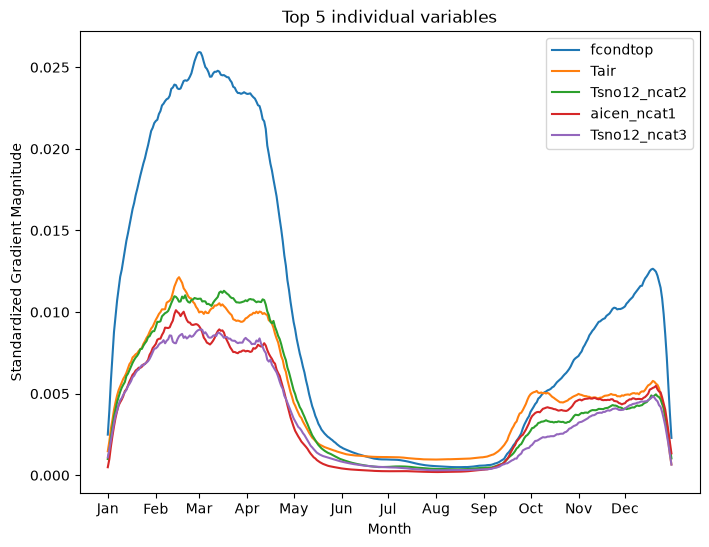

In [49]:
for i in (range(head)):
    ind = order[i]
    plt.plot(avg_abs_grad[:,ind],label = sort[i])
plt.xticks(month_starts, labels = month_names)
plt.ylabel("Gradient Magnitude (Standardized)")
plt.xlabel("Month")
plt.legend()
plt.title(f"Top {head} individual variables")
plt.show()

In [69]:
grouped = {var: [ind for ind, name in enumerate(training_vars) if name.startswith(var)] for var in GROUPED_VARS}
ungrouped = {ind for ind, name in enumerate(training_vars) if not any(name.startswith(var) for var in GROUPED_VARS)}
grouped_names = list(grouped) + [training_vars[i] for i in ungrouped]
grouped_grad = torch.stack([avg_abs_grad[:,index].sum(dim=1) for index in grouped.values()] + [avg_abs_grad[:,j] for j in ungrouped])

grouped_order = torch.argsort(grouped_grad.mean(dim =1))
grouped_order = torch.flip(grouped_order, dims=[0])
grouped_sort = [grouped_names[grouped_order[i]] for i in range(len(grouped_names))]
grouped_comp_list = []
for j in range(len(grouped_names)):
    name = grouped_sort[j]
    rank = j+1
    mag = round(float(grouped_grad.mean(dim=1)[grouped_order[j]]),4)
    if name in group:
        num = len(grouped[grouped_sort[j]])
    else:
        num = 1
    grouped_comp_list.append([name, rank, mag, num, round(mag/num,4)])
grouped_grad = grouped_grad.T
print(tabulate(grouped_comp_list, headers = ["Variable", "Rank", "Aggregate Average Magnitude of Gradient", "Number of channels", "Mean Average Magnitude of Gradient"]))

Variable      Rank    Aggregate Average Magnitude of Gradient    Number of channels    Mean Average Magnitude of Gradient
----------  ------  -----------------------------------------  --------------------  ------------------------------------
Tsno             1                                     0.0296                    15                                0.002
vsno             2                                     0.012                      5                                0.0024
aice             3                                     0.0104                     5                                0.0021
fcondtop         4                                     0.0095                     1                                0.0095
vice             5                                     0.0052                     5                                0.001
Tair             6                                     0.0048                     1                                0.0048


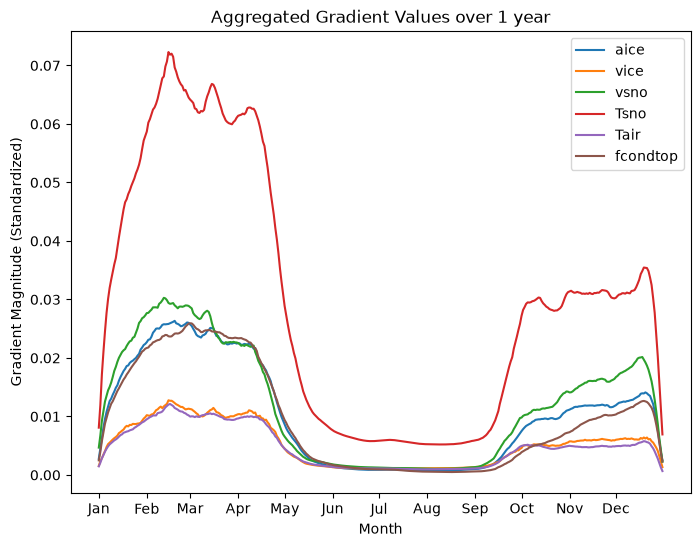

In [70]:
for i in range(len(grouped_names)):
    plt.plot(grouped_grad[:,i], label = grouped_names[i])
plt.legend()
plt.title("Aggregated Gradient Values over 1 year")
plt.xticks(month_starts, labels = month_names)
plt.ylabel("Gradient Magnitude (Standardized)")
plt.xlabel("Month")
plt.show()

## Physical Gradient Plots

In [97]:
grad_units = grad * y_sd 
grad_units = grad_units / sd[None, None,:] # ksno per physical unit

panels = {name: (grad_units[:,:,idx].sum(axis = 2)) for name, idx in grouped.items()}

for x in ungrouped:
    panels[training_vars[x]] = grad_units[:,:,x]

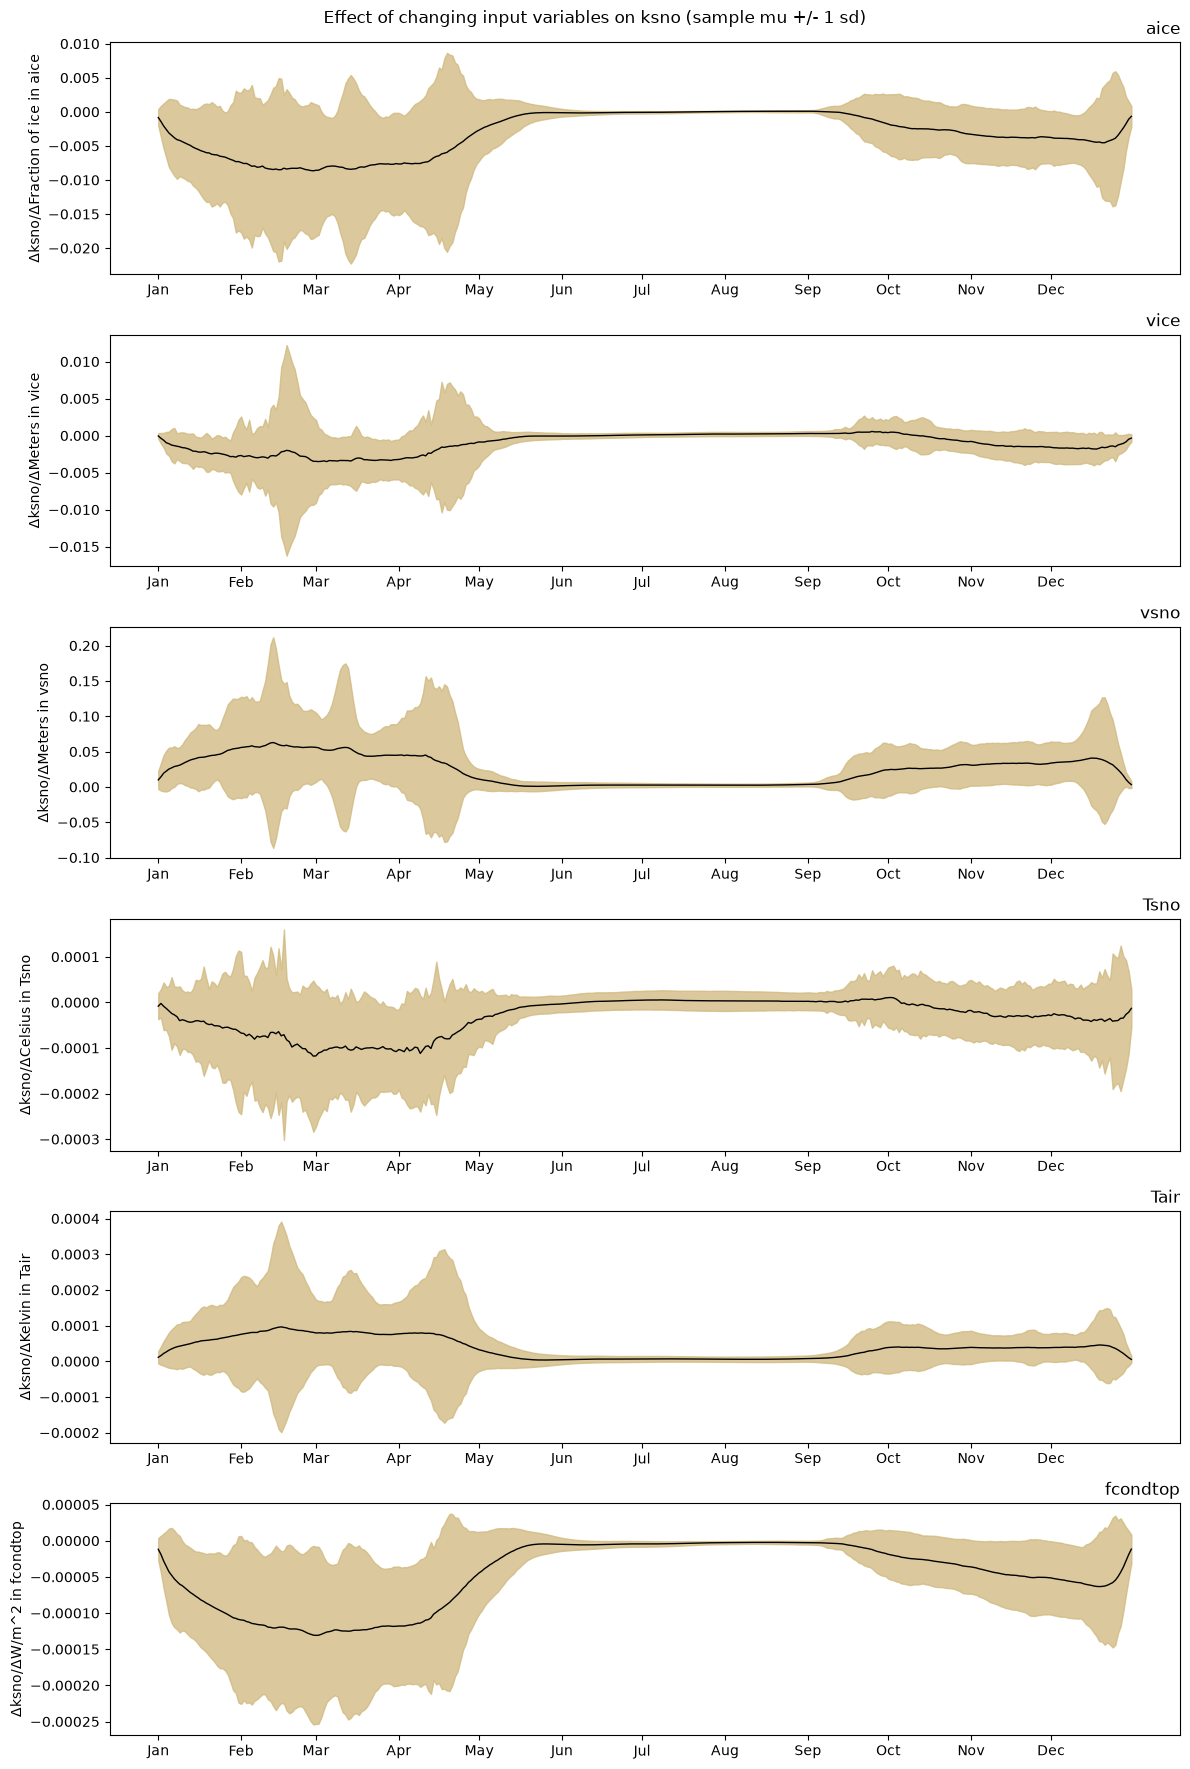

In [153]:
plt.figure(figsize = (12, 3*len(panels)))
i=1
xs = np.arange(len(sample_sd))
for name, panel in panels.items():
    plt.subplot(len(panels), 1, i)
    sample_mean = panel.mean(axis = 0)
    sample_sd = panel.std(axis = 0)
    plt.fill_between(xs,  sample_mean - sample_sd, sample_mean + sample_sd, alpha = 0.75, color = "#CFB87C")
    plt.plot(xs, sample_mean, lw = 1, color = "black")
    plt.ylabel(f"Δksno/Δ{units[name]} in {name}")
    plt.title(name, loc = "right")
    i+=1
    
    plt.xticks(month_starts, labels = month_names)
plt.suptitle("Effect of changing input variables on ksno (sample mu +/- 1 sd)")
plt.tight_layout()
plt.show()